In [1]:

import torch

print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


PyTorch: 2.14.1+cu130
GPU available: True
GPU: Tesla T4


In [2]:
!pip install -q datasets

In [3]:
from datasets import load_dataset

dataset = load_dataset("google-research-datasets/go_emotions")

README.md:   0%|          | 0.00/9.40k [00:00<?, ?B/s]

simplified/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.77MB            

simplified/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

simplified/validation-00000-of-00001.par(…): reconstructing file:   0%|          |  0.00B /  350kB            

simplified/validation-00000-of-00001.par(…): downloading bytes:           |  0.00B            

simplified/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  347kB            

simplified/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/43410 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5426 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5427 [00:00<?, ? examples/s]

In [4]:
print(dataset)

DatasetDict({
    train: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 43410
    })
    validation: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 5426
    })
    test: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 5427
    })
})


In [5]:
print(dataset["train"][0])

{'text': "My favourite food is anything I didn't have to cook myself.", 'labels': [27], 'id': 'eebbqej'}


In [6]:
print(dataset["train"].column_names)

['text', 'labels', 'id']


In [7]:
features = dataset["train"].features

print(features["labels"].feature.names)

['admiration', 'amusement', 'anger', 'annoyance', 'approval', 'caring', 'confusion', 'curiosity', 'desire', 'disappointment', 'disapproval', 'disgust', 'embarrassment', 'excitement', 'fear', 'gratitude', 'grief', 'joy', 'love', 'nervousness', 'optimism', 'pride', 'realization', 'relief', 'remorse', 'sadness', 'surprise', 'neutral']


In [8]:
emotion_names = features["labels"].feature.names

for i, emotion in enumerate(emotion_names):
    print(i, emotion)

0 admiration
1 amusement
2 anger
3 annoyance
4 approval
5 caring
6 confusion
7 curiosity
8 desire
9 disappointment
10 disapproval
11 disgust
12 embarrassment
13 excitement
14 fear
15 gratitude
16 grief
17 joy
18 love
19 nervousness
20 optimism
21 pride
22 realization
23 relief
24 remorse
25 sadness
26 surprise
27 neutral


In [9]:
import pandas as pd

train_df = dataset["train"].to_pandas()
val_df = dataset["validation"].to_pandas()
test_df = dataset["test"].to_pandas()

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

train_df.head()

Train: (43410, 3)
Validation: (5426, 3)
Test: (5427, 3)


,text,labels,id
0,My favourite food is anything I didn't have to...,[27],eebbqej
1,"Now if he does off himself, everyone will thin...",[27],ed00q6i
2,WHY THE FUCK IS BAYLESS ISOING,[2],eezlygj
3,To make her feel threatened,[14],ed7ypvh
4,Dirty Southern Wankers,[3],ed0bdzj


In [10]:
label_mapping = {
    17: 0,  # joy
    25: 1,  # sadness
    2: 2,   # anger
    14: 3,  # fear
    26: 4,  # surprise
    11: 5   # disgust
}

class_names = [
    "joy",
    "sadness",
    "anger",
    "fear",
    "surprise",
    "disgust"
]

print("Number of classes:", len(class_names))

for i, emotion in enumerate(class_names):
    print(f"{i}: {emotion}")

Number of classes: 6
0: joy
1: sadness
2: anger
3: fear
4: surprise
5: disgust


In [11]:
import pandas as pd
train_df = dataset["train"].to_pandas()
val_df = dataset["validation"].to_pandas()
test_df = dataset["test"].to_pandas()


def filter_emotions(df):
    df = df.copy()
    df = df[df["labels"].apply(len) == 1].copy()
    df["original_label"] = df["labels"].apply(lambda x: x[0])
    df = df[df["original_label"].isin(label_mapping)].copy()
    df["label"] = df["original_label"].map(label_mapping)

    return df[["text", "label", "id"]].reset_index(drop=True)

train_df = filter_emotions(train_df)
val_df = filter_emotions(val_df)
test_df = filter_emotions(test_df)


print("Filtered dataset sizes:")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))
print("Total:", len(train_df) + len(val_df) + len(test_df))

Filtered dataset sizes:
Train: 4343
Validation: 513
Test: 554
Total: 5410


In [12]:
for split_name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:

    print(f"\n{split_name} Distribution")

    counts = df["label"].value_counts().reindex(
        range(6), fill_value=0
    )

    for label_id, count in counts.items():
        print(
            f"{class_names[label_id]}: {count} "
            f"({count / len(df) * 100:.2f}%)"
        )


Train Distribution
joy: 853 (19.64%)
sadness: 817 (18.81%)
anger: 1025 (23.60%)
fear: 430 (9.90%)
surprise: 720 (16.58%)
disgust: 498 (11.47%)

Validation Distribution
joy: 106 (20.66%)
sadness: 84 (16.37%)
anger: 109 (21.25%)
fear: 58 (11.31%)
surprise: 95 (18.52%)
disgust: 61 (11.89%)

Test Distribution
joy: 93 (16.79%)
sadness: 102 (18.41%)
anger: 131 (23.65%)
fear: 65 (11.73%)
surprise: 87 (15.70%)
disgust: 76 (13.72%)


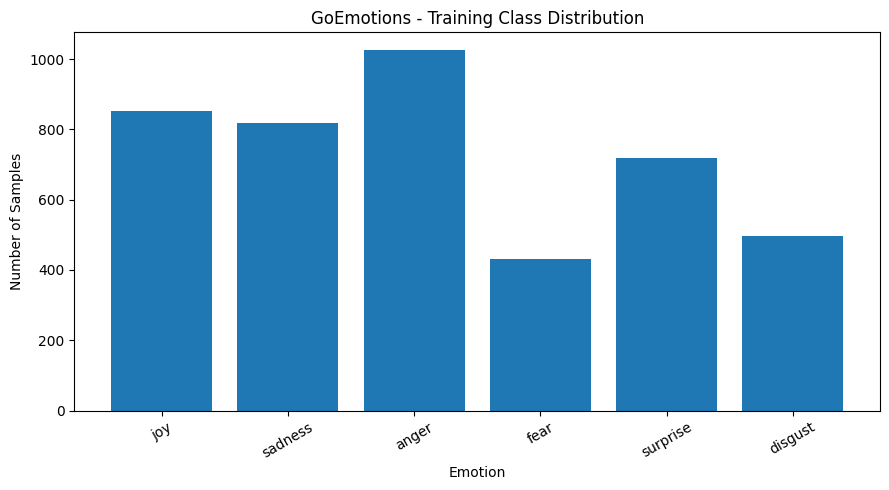

In [13]:
import matplotlib.pyplot as plt

class_counts = train_df["label"].value_counts().reindex(
    range(6), fill_value=0
)

plt.figure(figsize=(9, 5))

plt.bar(class_names, class_counts.values)

plt.title("GoEmotions - Training Class Distribution")
plt.xlabel("Emotion")
plt.ylabel("Number of Samples")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [14]:
!pip install -q nltk

In [15]:
import re
import nltk

def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"<.*?>", "", text)
    text = re.sub(r"[^a-z0-9\s']", " ", text)
    text = re.sub(r"\s+", " ", text).strip()

    return text


for df in [train_df, val_df, test_df]:

    df["clean_text"] = df["text"].apply(clean_text)


print("Original:")
print(train_df["text"].iloc[0])

print("\nCleaned:")
print(train_df["clean_text"].iloc[0])

Original:
WHY THE FUCK IS BAYLESS ISOING

Cleaned:
why the fuck is bayless isoing


In [16]:
def tokenize(text):
    return text.split()


for df in [train_df, val_df, test_df]:

    df["tokens"] = df["clean_text"].apply(tokenize)


print("Original text:")
print(train_df["text"].iloc[0])

print("\nTokens:")
print(train_df["tokens"].iloc[0])

Original text:
WHY THE FUCK IS BAYLESS ISOING

Tokens:
['why', 'the', 'fuck', 'is', 'bayless', 'isoing']


count    4343.000000
mean       12.482616
std         6.762409
min         1.000000
25%         7.000000
50%        12.000000
75%        18.000000
max        31.000000
Name: sequence_length, dtype: float64


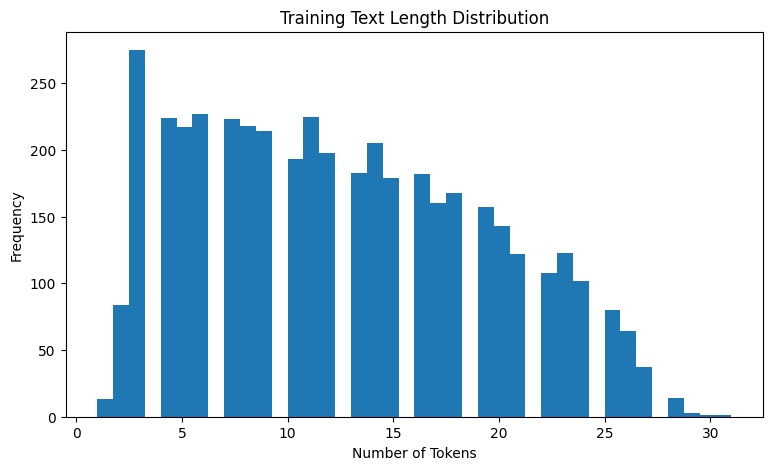

95th percentile: 24.0


In [17]:
train_df["sequence_length"] = train_df["tokens"].apply(len)

print(train_df["sequence_length"].describe())

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.hist(train_df["sequence_length"], bins=40)

plt.xlabel("Number of Tokens")
plt.ylabel("Frequency")
plt.title("Training Text Length Distribution")

plt.show()

print(
    "95th percentile:",
    train_df["sequence_length"].quantile(0.95)
)

In [18]:
MAX_LEN = 30

PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"

PAD_IDX = 0
UNK_IDX = 1

print("Maximum sequence length:", MAX_LEN)

Maximum sequence length: 30


In [19]:
from collections import Counter

word_counts = Counter()
for tokens in train_df["tokens"]:
    word_counts.update(tokens)

vocab = {
    PAD_TOKEN: PAD_IDX,
    UNK_TOKEN: UNK_IDX
}

for word, count in word_counts.most_common():
    if count >= 1:
        vocab[word] = len(vocab)

id_to_word = {idx: word for word, idx in vocab.items()}

print("Vocabulary size:", len(vocab))
print("\nFirst 20 vocabulary entries:")

for word, idx in list(vocab.items())[:20]:
    print(word, ":", idx)

Vocabulary size: 7112

First 20 vocabulary entries:
<PAD> : 0
<UNK> : 1
i : 2
the : 3
a : 4
to : 5
that : 6
and : 7
is : 8
it : 9
you : 10
name : 11
this : 12
of : 13
in : 14
was : 15
my : 16
for : 17
me : 18
so : 19


In [20]:
def encode_text(tokens, vocab):

    encoded = [
        vocab.get(token, UNK_IDX)
        for token in tokens
    ]

    encoded = encoded[:MAX_LEN]
    padding_length = MAX_LEN - len(encoded)

    encoded += [PAD_IDX] * padding_length

    return encoded


for df in [train_df, val_df, test_df]:

    df["input_ids"] = df["tokens"].apply(
        lambda tokens: encode_text(tokens, vocab)
    )


print("Original tokens:")
print(train_df["tokens"].iloc[0])

print("\nEncoded sequence:")
print(train_df["input_ids"].iloc[0])

print("\nDecoded sequence:")

decoded = [
    id_to_word[idx]
    for idx in train_df["input_ids"].iloc[0]
]

print(decoded)

Original tokens:
['why', 'the', 'fuck', 'is', 'bayless', 'isoing']

Encoded sequence:
[106, 3, 39, 8, 2930, 2931, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

Decoded sequence:
['why', 'the', 'fuck', 'is', 'bayless', 'isoing', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>', '<PAD>']


In [21]:
import torch

def create_tensors(df):

    X = torch.tensor(
        df["input_ids"].tolist(),
        dtype=torch.long
    )
    y = torch.tensor(
        df["label"].tolist(),
        dtype=torch.long
    )

    return X, y


X_train, y_train = create_tensors(train_df)
X_val, y_val = create_tensors(val_df)
X_test, y_test = create_tensors(test_df)


print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: torch.Size([4343, 30]) torch.Size([4343])
Validation: torch.Size([513, 30]) torch.Size([513])
Testing: torch.Size([554, 30]) torch.Size([554])


In [22]:
for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:

    total_tokens = sum(len(tokens) for tokens in df["tokens"])

    unknown_tokens = sum(
        sum(1 for token in tokens if token not in vocab)
        for tokens in df["tokens"]
    )

    padding_tokens = sum(
        sum(1 for idx in ids if idx == PAD_IDX)
        for ids in df["input_ids"]
    )

    print(f"\n{name}")
    print("Total tokens:", total_tokens)
    print("Unknown tokens:", unknown_tokens)
    print("Padding tokens:", padding_tokens)


Train
Total tokens: 54212
Unknown tokens: 0
Padding tokens: 76079

Validation
Total tokens: 6698
Unknown tokens: 587
Padding tokens: 8692

Test
Total tokens: 7005
Unknown tokens: 574
Padding tokens: 9615


In [23]:
!pip install -q gensim

In [24]:
import gensim.downloader as api

glove = api.load("glove-wiki-gigaword-100")

print("GloVe loaded successfully!")
print("Embedding dimension:", glove.vector_size)
print("Vocabulary size:", len(glove))

[==================================================] 100.0% 128.1/128.1MB downloaded
GloVe loaded successfully!
Embedding dimension: 100
Vocabulary size: 400000


In [27]:
import numpy as np

EMBEDDING_DIM = 100

embedding_matrix = np.random.normal(
    loc=0,
    scale=0.1,
    size=(len(vocab), EMBEDDING_DIM)
).astype(np.float32)

embedding_matrix[PAD_IDX] = np.zeros(EMBEDDING_DIM)


embedding_matrix[UNK_IDX] = np.mean(
    glove.vectors,
    axis=0
)

matched_words = 0

for word, idx in vocab.items():

    if word in [PAD_TOKEN, UNK_TOKEN]:
        continue

    if word in glove:
        embedding_matrix[idx] = glove[word]
        matched_words += 1

print("Embedding matrix shape:", embedding_matrix.shape)
print("Matched words:", matched_words)

print(
    "GloVe coverage:",
    f"{matched_words / (len(vocab) - 2) * 100:.2f}%"
)

Embedding matrix shape: (7112, 100)
Matched words: 6573
GloVe coverage: 92.45%


In [28]:
embedding_matrix = torch.tensor(
    embedding_matrix,
    dtype=torch.float32
)

print(embedding_matrix.shape)
print(embedding_matrix.dtype)

torch.Size([7112, 100])
torch.float32


In [29]:
import torch
import torch.nn as nn
import torch.optim as optim

import numpy as np
import random

from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score
from sklearn.utils.class_weight import compute_class_weight


SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [30]:
from torch.utils.data import TensorDataset, DataLoader

# Calculate actual sequence lengths
train_lengths = (X_train != PAD_IDX).sum(dim=1)
val_lengths = (X_val != PAD_IDX).sum(dim=1)
test_lengths = (X_test != PAD_IDX).sum(dim=1)

# Create datasets
train_dataset = TensorDataset(
    X_train, train_lengths, y_train
)

val_dataset = TensorDataset(
    X_val, val_lengths, y_val
)

test_dataset = TensorDataset(
    X_test, test_lengths, y_test
)

BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

print("\nExample sequence length:", train_lengths[0].item())

Training batches: 68
Validation batches: 9
Testing batches: 9

Example sequence length: 6


In [31]:
classes = np.unique(y_train.numpy())

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train.numpy()
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)

print("Class weights:")

for emotion, weight in zip(class_names, class_weights):
    print(f"{emotion}: {weight.item():.4f}")

Class weights:
joy: 0.8486
sadness: 0.8860
anger: 0.7062
fear: 1.6833
surprise: 1.0053
disgust: 1.4535


In [32]:
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence


class LSTMClassifier(nn.Module):

    def __init__(
        self,
        embedding_matrix,
        hidden_dim=128,
        num_classes=6,
        dropout=0.3
    ):

        super(LSTMClassifier, self).__init__()

        vocab_size, embedding_dim = embedding_matrix.shape


        self.embedding = nn.Embedding.from_pretrained(
            embedding_matrix,
            freeze=False,
            padding_idx=PAD_IDX
        )

        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=1,
            batch_first=True
        )

        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(
            hidden_dim,
            num_classes
        )

    def forward(self, input_ids, lengths):


        embedded = self.embedding(input_ids)

        packed = pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        packed_output, (hidden, cell) = self.lstm(packed)
        final_hidden = hidden[-1]
        output = self.dropout(final_hidden)
        logits = self.fc(output)

        return logits

In [33]:
model = LSTMClassifier(
    embedding_matrix=embedding_matrix,
    hidden_dim=128,
    num_classes=6,
    dropout=0.3
).to(device)

criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print(model)

LSTMClassifier(
  (embedding): Embedding(7112, 100, padding_idx=0)
  (lstm): LSTM(100, 128, batch_first=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=128, out_features=6, bias=True)
)


In [34]:
sample_ids, sample_lengths, sample_labels = next(
    iter(train_loader)
)

sample_ids = sample_ids.to(device)
sample_lengths = sample_lengths.to(device)

model.eval()

with torch.no_grad():

    predictions = model(
        sample_ids,
        sample_lengths
    )

print("Input shape:", sample_ids.shape)
print("Output shape:", predictions.shape)

Input shape: torch.Size([64, 30])
Output shape: torch.Size([64, 6])


In [35]:
from sklearn.metrics import accuracy_score, f1_score

def train_one_epoch(model, loader, criterion, optimizer):

    model.train()

    total_loss = 0

    all_predictions = []
    all_labels = []

    for input_ids, lengths, labels in loader:

        input_ids = input_ids.to(device)
        lengths = lengths.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(input_ids, lengths)

        loss = criterion(outputs, labels)

        loss.backward()

        # Prevent exploding gradients
        nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        total_loss += loss.item()

        predictions = torch.argmax(outputs, dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    avg_loss = total_loss / len(loader)

    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    return avg_loss, accuracy, macro_f1


def evaluate(model, loader, criterion):

    model.eval()

    total_loss = 0

    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for input_ids, lengths, labels in loader:

            input_ids = input_ids.to(device)
            lengths = lengths.to(device)
            labels = labels.to(device)

            outputs = model(input_ids, lengths)

            loss = criterion(outputs, labels)

            total_loss += loss.item()

            predictions = torch.argmax(outputs, dim=1)

            all_predictions.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    avg_loss = total_loss / len(loader)

    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    return avg_loss, accuracy, macro_f1

In [36]:
import copy

EPOCHS = 20
PATIENCE = 4

best_val_f1 = 0
patience_counter = 0

history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": [],
    "train_f1": [],
    "val_f1": []
}

for epoch in range(EPOCHS):

    train_loss, train_acc, train_f1 = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer
    )

    val_loss, val_acc, val_f1 = evaluate(
        model,
        val_loader,
        criterion
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    history["train_accuracy"].append(train_acc)
    history["val_accuracy"].append(val_acc)

    history["train_f1"].append(train_f1)
    history["val_f1"].append(val_f1)

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    print(f"Train Loss: {train_loss:.4f}")
    print(f"Val Loss: {val_loss:.4f}")

    print(f"Train Accuracy: {train_acc:.4f}")
    print(f"Val Accuracy: {val_acc:.4f}")

    print(f"Train Macro F1: {train_f1:.4f}")
    print(f"Val Macro F1: {val_f1:.4f}")

    # Save the best model
    if val_f1 > best_val_f1:

        best_val_f1 = val_f1

        best_model_state = copy.deepcopy(
            model.state_dict()
        )

        torch.save(
            best_model_state,
            "/content/best_lstm.pt"
        )

        patience_counter = 0

        print("Best model saved!")

    else:

        patience_counter += 1

        print(
            f"Early stopping counter: "
            f"{patience_counter}/{PATIENCE}"
        )

    if patience_counter >= PATIENCE:

        print("\nEarly stopping triggered!")
        break



model.load_state_dict(best_model_state)

print("\nTraining completed!")
print("Best Validation Macro F1:", best_val_f1)


Epoch 1/20
Train Loss: 1.6983
Val Loss: 1.5666
Train Accuracy: 0.3189
Val Accuracy: 0.4074
Train Macro F1: 0.2992
Val Macro F1: 0.4005
Best model saved!

Epoch 2/20
Train Loss: 1.3295
Val Loss: 1.3105
Train Accuracy: 0.5542
Val Accuracy: 0.5867
Train Macro F1: 0.5193
Val Macro F1: 0.5565
Best model saved!

Epoch 3/20
Train Loss: 1.0125
Val Loss: 1.0660
Train Accuracy: 0.6804
Val Accuracy: 0.6745
Train Macro F1: 0.6533
Val Macro F1: 0.6557
Best model saved!

Epoch 4/20
Train Loss: 0.7672
Val Loss: 0.8385
Train Accuracy: 0.7672
Val Accuracy: 0.7271
Train Macro F1: 0.7507
Val Macro F1: 0.7109
Best model saved!

Epoch 5/20
Train Loss: 0.5963
Val Loss: 0.7176
Train Accuracy: 0.8227
Val Accuracy: 0.7349
Train Macro F1: 0.8097
Val Macro F1: 0.7210
Best model saved!

Epoch 6/20
Train Loss: 0.4604
Val Loss: 0.7677
Train Accuracy: 0.8618
Val Accuracy: 0.7524
Train Macro F1: 0.8534
Val Macro F1: 0.7464
Best model saved!

Epoch 7/20
Train Loss: 0.3596
Val Loss: 0.7057
Train Accuracy: 0.8971
Val A

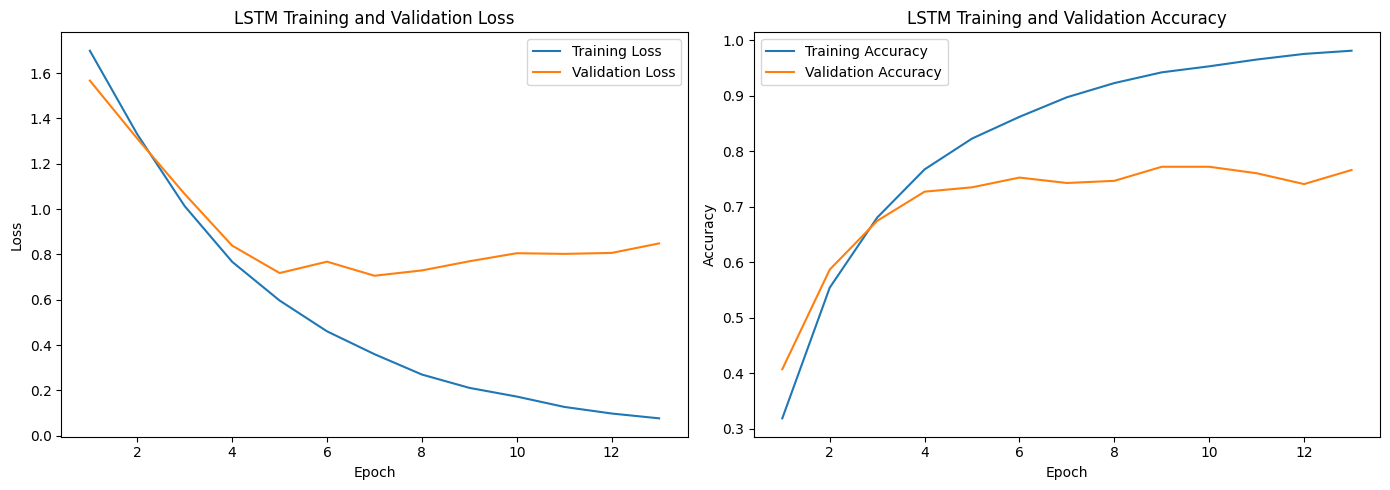

In [37]:
import matplotlib.pyplot as plt

epochs_range = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(14, 5))

# Loss
plt.subplot(1, 2, 1)

plt.plot(
    epochs_range,
    history["train_loss"],
    label="Training Loss"
)

plt.plot(
    epochs_range,
    history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("LSTM Training and Validation Loss")
plt.legend()

# Accuracy
plt.subplot(1, 2, 2)

plt.plot(
    epochs_range,
    history["train_accuracy"],
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("LSTM Training and Validation Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

In [38]:
from sklearn.metrics import classification_report

test_loss, test_acc, test_f1 = evaluate(
    model,
    test_loader,
    criterion
)

print("LSTM Test Results")
print("-------------------------")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test Macro F1: {test_f1:.4f}")

LSTM Test Results
-------------------------
Test Loss: 0.8227
Test Accuracy: 0.7617
Test Macro F1: 0.7639


In [39]:
class GRUClassifier(nn.Module):

    def __init__(
        self,
        embedding_matrix,
        hidden_dim=128,
        num_classes=6,
        dropout=0.3
    ):

        super(GRUClassifier, self).__init__()

        vocab_size, embedding_dim = embedding_matrix.shape

        self.embedding = nn.Embedding.from_pretrained(
            embedding_matrix,
            freeze=False,
            padding_idx=PAD_IDX
        )

        self.gru = nn.GRU(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=1,
            batch_first=True
        )

        self.dropout = nn.Dropout(dropout)

        self.fc = nn.Linear(
            hidden_dim,
            num_classes
        )

    def forward(self, input_ids, lengths):

        embedded = self.embedding(input_ids)

        packed = pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        packed_output, hidden = self.gru(packed)

        final_hidden = hidden[-1]

        output = self.dropout(final_hidden)

        logits = self.fc(output)

        return logits

In [40]:
gru_model = GRUClassifier(
    embedding_matrix=embedding_matrix,
    hidden_dim=128,
    num_classes=6,
    dropout=0.3
).to(device)

gru_criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

gru_optimizer = optim.Adam(
    gru_model.parameters(),
    lr=0.001
)

print(gru_model)

GRUClassifier(
  (embedding): Embedding(7112, 100, padding_idx=0)
  (gru): GRU(100, 128, batch_first=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=128, out_features=6, bias=True)
)


In [41]:
sample_ids, sample_lengths, sample_labels = next(
    iter(train_loader)
)

sample_ids = sample_ids.to(device)
sample_lengths = sample_lengths.to(device)

gru_model.eval()

with torch.no_grad():

    outputs = gru_model(
        sample_ids,
        sample_lengths
    )

print("Input shape:", sample_ids.shape)
print("Output shape:", outputs.shape)

Input shape: torch.Size([64, 30])
Output shape: torch.Size([64, 6])


In [42]:
import copy

EPOCHS = 20
PATIENCE = 4

best_gru_f1 = 0
gru_patience_counter = 0

gru_history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": [],
    "train_f1": [],
    "val_f1": []
}

best_gru_state = None

for epoch in range(EPOCHS):

    train_loss, train_acc, train_f1 = train_one_epoch(
        gru_model,
        train_loader,
        gru_criterion,
        gru_optimizer
    )

    val_loss, val_acc, val_f1 = evaluate(
        gru_model,
        val_loader,
        gru_criterion
    )

    gru_history["train_loss"].append(train_loss)
    gru_history["val_loss"].append(val_loss)

    gru_history["train_accuracy"].append(train_acc)
    gru_history["val_accuracy"].append(val_acc)

    gru_history["train_f1"].append(train_f1)
    gru_history["val_f1"].append(val_f1)

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    print(f"Train Loss: {train_loss:.4f}")
    print(f"Val Loss: {val_loss:.4f}")

    print(f"Train Accuracy: {train_acc:.4f}")
    print(f"Val Accuracy: {val_acc:.4f}")

    print(f"Train Macro F1: {train_f1:.4f}")
    print(f"Val Macro F1: {val_f1:.4f}")

    if val_f1 > best_gru_f1:

        best_gru_f1 = val_f1

        best_gru_state = copy.deepcopy(
            gru_model.state_dict()
        )

        torch.save(
            best_gru_state,
            "/content/best_gru.pt"
        )

        gru_patience_counter = 0

        print("Best GRU model saved!")

    else:

        gru_patience_counter += 1

        print(
            f"Early stopping: "
            f"{gru_patience_counter}/{PATIENCE}"
        )

    if gru_patience_counter >= PATIENCE:

        print("\nEarly stopping triggered!")
        break


gru_model.load_state_dict(best_gru_state)

print("\nGRU training completed!")
print("Best validation Macro F1:", best_gru_f1)


Epoch 1/20
Train Loss: 1.6774
Val Loss: 1.6211
Train Accuracy: 0.3212
Val Accuracy: 0.4464
Train Macro F1: 0.3082
Val Macro F1: 0.4052
Best GRU model saved!

Epoch 2/20
Train Loss: 1.2091
Val Loss: 1.0925
Train Accuracy: 0.5867
Val Accuracy: 0.6823
Train Macro F1: 0.5591
Val Macro F1: 0.6554
Best GRU model saved!

Epoch 3/20
Train Loss: 0.8016
Val Loss: 0.7479
Train Accuracy: 0.7497
Val Accuracy: 0.7544
Train Macro F1: 0.7348
Val Macro F1: 0.7431
Best GRU model saved!

Epoch 4/20
Train Loss: 0.5585
Val Loss: 0.6824
Train Accuracy: 0.8264
Val Accuracy: 0.7778
Train Macro F1: 0.8174
Val Macro F1: 0.7692
Best GRU model saved!

Epoch 5/20
Train Loss: 0.4222
Val Loss: 0.6037
Train Accuracy: 0.8717
Val Accuracy: 0.7934
Train Macro F1: 0.8651
Val Macro F1: 0.7853
Best GRU model saved!

Epoch 6/20
Train Loss: 0.3176
Val Loss: 0.6163
Train Accuracy: 0.9067
Val Accuracy: 0.7797
Train Macro F1: 0.9012
Val Macro F1: 0.7713
Early stopping: 1/4

Epoch 7/20
Train Loss: 0.2400
Val Loss: 0.6241
Train 

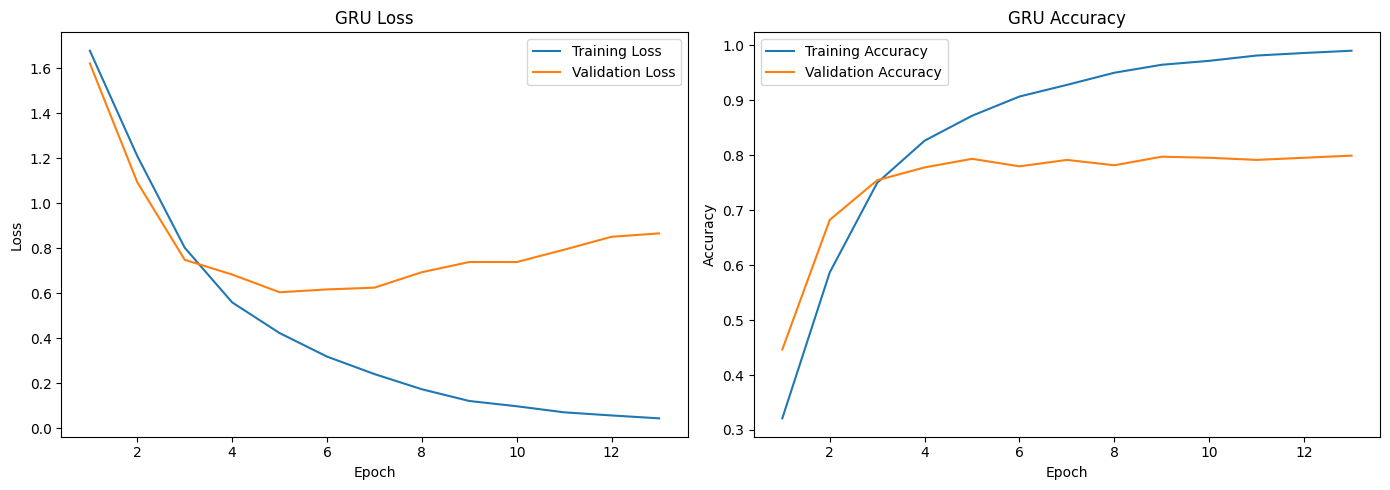

In [43]:
epochs_range = range(
    1, len(gru_history["train_loss"]) + 1
)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)

plt.plot(
    epochs_range,
    gru_history["train_loss"],
    label="Training Loss"
)

plt.plot(
    epochs_range,
    gru_history["val_loss"],
    label="Validation Loss"
)

plt.title("GRU Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)

plt.plot(
    epochs_range,
    gru_history["train_accuracy"],
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    gru_history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("GRU Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

In [44]:
gru_test_loss, gru_test_acc, gru_test_f1 = evaluate(
    gru_model,
    test_loader,
    gru_criterion
)

print("GRU Test Results")
print("-------------------------")
print(f"Test Loss: {gru_test_loss:.4f}")
print(f"Test Accuracy: {gru_test_acc:.4f}")
print(f"Test Macro F1: {gru_test_f1:.4f}")

GRU Test Results
-------------------------
Test Loss: 0.8858
Test Accuracy: 0.7708
Test Macro F1: 0.7722


In [45]:
class BiLSTMAttention(nn.Module):

    def __init__(
        self,
        embedding_matrix,
        hidden_dim=128,
        num_classes=6,
        dropout=0.3
    ):
        super().__init__()

        vocab_size, embedding_dim = embedding_matrix.shape

        self.embedding = nn.Embedding.from_pretrained(
            embedding_matrix,
            freeze=False,
            padding_idx=PAD_IDX
        )

        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=1,
            batch_first=True,
            bidirectional=True
        )

        self.attention = nn.Linear(hidden_dim * 2, 1)

        self.dropout = nn.Dropout(dropout)

        self.fc = nn.Linear(hidden_dim * 2, num_classes)

    def forward(self, input_ids, lengths, return_attention=False):

        embedded = self.embedding(input_ids)

        packed = pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        packed_output, _ = self.lstm(packed)

        lstm_output, _ = nn.utils.rnn.pad_packed_sequence(
            packed_output,
            batch_first=True,
            total_length=input_ids.size(1)
        )
        attention_scores = self.attention(lstm_output).squeeze(-1)

        mask = input_ids != PAD_IDX
        attention_scores = attention_scores.masked_fill(
            ~mask,
            -1e9
        )

        attention_weights = torch.softmax(
            attention_scores,
            dim=1
        )

        context = torch.sum(
            lstm_output * attention_weights.unsqueeze(-1),
            dim=1
        )

        output = self.dropout(context)

        logits = self.fc(output)

        if return_attention:
            return logits, attention_weights

        return logits

In [46]:
bilstm_model = BiLSTMAttention(
    embedding_matrix=embedding_matrix,
    hidden_dim=128,
    num_classes=6,
    dropout=0.3
).to(device)

bilstm_criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

bilstm_optimizer = optim.Adam(
    bilstm_model.parameters(),
    lr=0.001
)

print(bilstm_model)

BiLSTMAttention(
  (embedding): Embedding(7112, 100, padding_idx=0)
  (lstm): LSTM(100, 128, batch_first=True, bidirectional=True)
  (attention): Linear(in_features=256, out_features=1, bias=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=256, out_features=6, bias=True)
)


In [47]:
sample_ids, sample_lengths, sample_labels = next(iter(train_loader))

sample_ids = sample_ids.to(device)
sample_lengths = sample_lengths.to(device)

bilstm_model.eval()

with torch.no_grad():
    logits, attention_weights = bilstm_model(
        sample_ids,
        sample_lengths,
        return_attention=True
    )

print("Logits shape:", logits.shape)
print("Attention shape:", attention_weights.shape)

Logits shape: torch.Size([64, 6])
Attention shape: torch.Size([64, 30])


In [48]:
EPOCHS = 20
PATIENCE = 4

best_val_f1 = 0
patience_counter = 0

train_losses_bilstm = []
val_losses_bilstm = []

train_accs_bilstm = []
val_accs_bilstm = []

train_f1s_bilstm = []
val_f1s_bilstm = []

best_bilstm_state = None

In [49]:
for epoch in range(EPOCHS):

    train_loss, train_acc, train_f1 = train_one_epoch(
        bilstm_model,
        train_loader,
        bilstm_criterion,
        bilstm_optimizer
    )

    val_loss, val_acc, val_f1 = evaluate(
        bilstm_model,
        val_loader,
        bilstm_criterion
    )

    train_losses_bilstm.append(train_loss)
    val_losses_bilstm.append(val_loss)

    train_accs_bilstm.append(train_acc)
    val_accs_bilstm.append(val_acc)

    train_f1s_bilstm.append(train_f1)
    val_f1s_bilstm.append(val_f1)

    print(f"\nEpoch {epoch+1}/{EPOCHS}")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Val Loss: {val_loss:.4f}")
    print(f"Train Accuracy: {train_acc:.4f}")
    print(f"Val Accuracy: {val_acc:.4f}")
    print(f"Train Macro F1: {train_f1:.4f}")
    print(f"Val Macro F1: {val_f1:.4f}")

    if val_f1 > best_val_f1:

        best_val_f1 = val_f1
        patience_counter = 0

        best_bilstm_state = {
            key: value.detach().cpu().clone()
            for key, value in bilstm_model.state_dict().items()
        }

        torch.save(
            best_bilstm_state,
            "/content/best_bilstm_attention.pt"
        )

        print("Best BiLSTM Attention model saved!")

    else:
        patience_counter += 1
        print(f"Early stopping: {patience_counter}/{PATIENCE}")

    if patience_counter >= PATIENCE:
        print("\nEarly stopping triggered!")
        break

bilstm_model.load_state_dict(best_bilstm_state)
bilstm_model.to(device)

print("\nBiLSTM + Attention training completed!")
print(f"Best validation Macro F1: {best_val_f1:.4f}")


Epoch 1/20
Train Loss: 1.6664
Val Loss: 1.4259
Train Accuracy: 0.3369
Val Accuracy: 0.5088
Train Macro F1: 0.3361
Val Macro F1: 0.4611
Best BiLSTM Attention model saved!

Epoch 2/20
Train Loss: 1.1063
Val Loss: 0.9089
Train Accuracy: 0.6332
Val Accuracy: 0.7115
Train Macro F1: 0.6050
Val Macro F1: 0.7076
Best BiLSTM Attention model saved!

Epoch 3/20
Train Loss: 0.6919
Val Loss: 0.6205
Train Accuracy: 0.7838
Val Accuracy: 0.7856
Train Macro F1: 0.7742
Val Macro F1: 0.7786
Best BiLSTM Attention model saved!

Epoch 4/20
Train Loss: 0.4986
Val Loss: 0.5965
Train Accuracy: 0.8391
Val Accuracy: 0.7836
Train Macro F1: 0.8327
Val Macro F1: 0.7773
Early stopping: 1/4

Epoch 5/20
Train Loss: 0.3887
Val Loss: 0.5595
Train Accuracy: 0.8745
Val Accuracy: 0.7973
Train Macro F1: 0.8688
Val Macro F1: 0.7897
Best BiLSTM Attention model saved!

Epoch 6/20
Train Loss: 0.2901
Val Loss: 0.5706
Train Accuracy: 0.9086
Val Accuracy: 0.7973
Train Macro F1: 0.9030
Val Macro F1: 0.7925
Best BiLSTM Attention mo

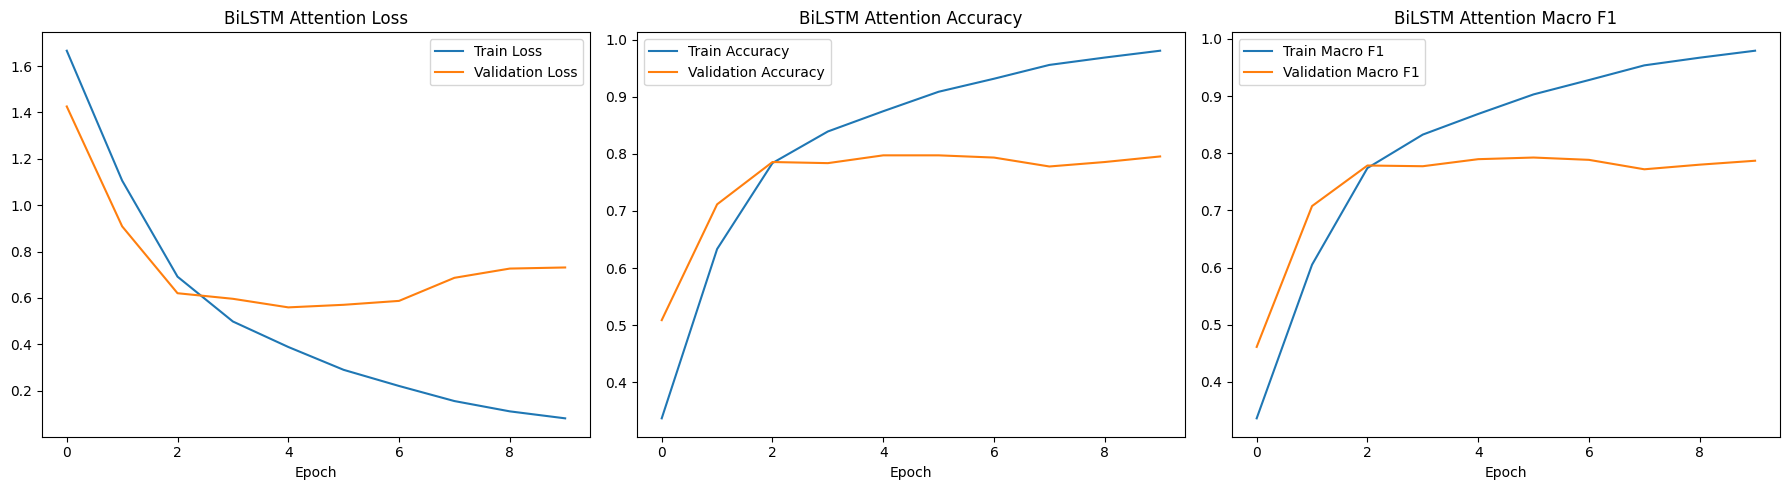

In [50]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(train_losses_bilstm, label="Train Loss")
axes[0].plot(val_losses_bilstm, label="Validation Loss")
axes[0].set_title("BiLSTM Attention Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(train_accs_bilstm, label="Train Accuracy")
axes[1].plot(val_accs_bilstm, label="Validation Accuracy")
axes[1].set_title("BiLSTM Attention Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()

axes[2].plot(train_f1s_bilstm, label="Train Macro F1")
axes[2].plot(val_f1s_bilstm, label="Validation Macro F1")
axes[2].set_title("BiLSTM Attention Macro F1")
axes[2].set_xlabel("Epoch")
axes[2].legend()

plt.tight_layout()
plt.show()

In [51]:
bilstm_test_loss, bilstm_test_acc, bilstm_test_f1 = evaluate(
    bilstm_model,
    test_loader,
    bilstm_criterion
)

print("\nBiLSTM + Attention Test Results")
print("-------------------------------")
print(f"Test Loss: {bilstm_test_loss:.4f}")
print(f"Test Accuracy: {bilstm_test_acc:.4f}")
print(f"Test Macro F1: {bilstm_test_f1:.4f}")


BiLSTM + Attention Test Results
-------------------------------
Test Loss: 0.6775
Test Accuracy: 0.7888
Test Macro F1: 0.7913


In [53]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

bilstm_model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for input_ids, lengths, labels in test_loader:

        input_ids = input_ids.to(device)
        lengths = lengths.to(device)

        outputs = bilstm_model(input_ids, lengths)

        predictions = torch.argmax(outputs, dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

print(classification_report(
    all_labels,
    all_predictions,
    target_names=class_names,
    digits=4,
    zero_division=0
))

              precision    recall  f1-score   support

         joy     0.8617    0.8710    0.8663        93
     sadness     0.8333    0.7843    0.8081       102
       anger     0.7698    0.7405    0.7549       131
        fear     0.8235    0.8615    0.8421        65
    surprise     0.7471    0.7471    0.7471        87
     disgust     0.6988    0.7632    0.7296        76

    accuracy                         0.7888       554
   macro avg     0.7891    0.7946    0.7913       554
weighted avg     0.7899    0.7888    0.7889       554



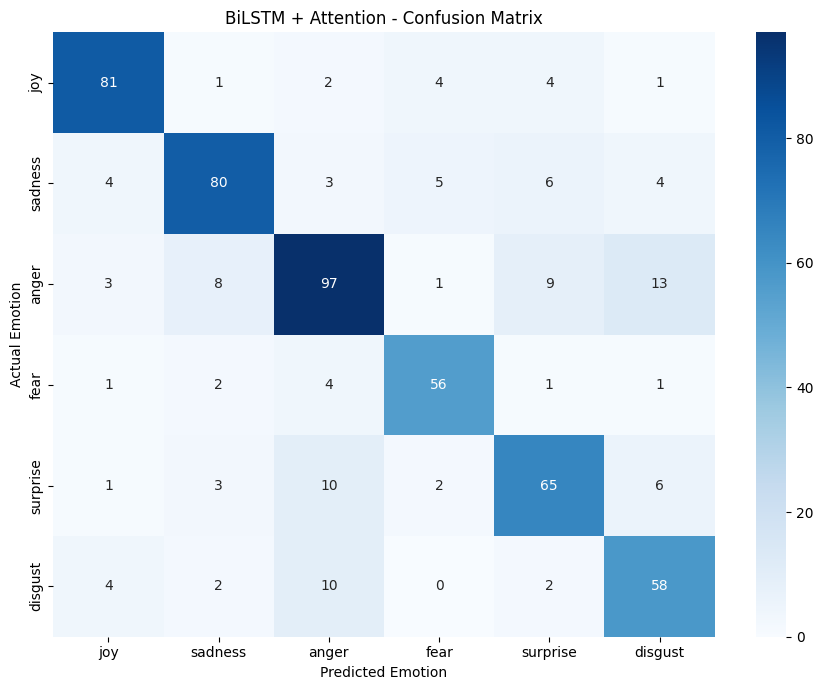

In [54]:
cm = confusion_matrix(
    all_labels,
    all_predictions
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.title("BiLSTM + Attention - Confusion Matrix")

plt.tight_layout()
plt.show()

In [55]:
!pip install -q transformers datasets accelerate evaluate

In [56]:
import torch
import transformers
import datasets

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
Transformers: 5.22.1
Datasets: 4.8.5
GPU available: True
GPU: Tesla T4


In [57]:
from transformers import AutoTokenizer

MODEL_NAME = "distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("Tokenizer loaded successfully!")
print("Vocabulary size:", tokenizer.vocab_size)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Tokenizer loaded successfully!
Vocabulary size: 30522


In [58]:
from datasets import Dataset, DatasetDict

train_hf = Dataset.from_pandas(
    train_df[["text", "label"]].reset_index(drop=True)
)

val_hf = Dataset.from_pandas(
    val_df[["text", "label"]].reset_index(drop=True)
)

test_hf = Dataset.from_pandas(
    test_df[["text", "label"]].reset_index(drop=True)
)

emotion_dataset = DatasetDict({
    "train": train_hf,
    "validation": val_hf,
    "test": test_hf
})

print(emotion_dataset)

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 4343
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 513
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 554
    })
})


In [59]:
MAX_LENGTH = 64

def tokenize_function(examples):

    return tokenizer(
        examples["text"],
        padding="max_length",
        truncation=True,
        max_length=MAX_LENGTH
    )

tokenized_dataset = emotion_dataset.map(
    tokenize_function,
    batched=True
)

tokenized_dataset = tokenized_dataset.rename_column(
    "label", "labels"
)

tokenized_dataset.set_format(
    type="torch",
    columns=["input_ids", "attention_mask", "labels"]
)

print(tokenized_dataset)

Map:   0%|          | 0/4343 [00:00<?, ? examples/s]

Map:   0%|          | 0/513 [00:00<?, ? examples/s]

Map:   0%|          | 0/554 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 4343
    })
    validation: Dataset({
        features: ['text', 'labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 513
    })
    test: Dataset({
        features: ['text', 'labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 554
    })
})


In [60]:
sample = tokenized_dataset["train"][0]

print("Input IDs shape:", sample["input_ids"].shape)
print("Attention Mask shape:", sample["attention_mask"].shape)
print("Label:", sample["labels"])

print(
    tokenizer.decode(
        sample["input_ids"],
        skip_special_tokens=True
    )
)

Input IDs shape: torch.Size([64])
Attention Mask shape: torch.Size([64])
Label: tensor(2)
why the fuck is bayless isoing


In [61]:
from transformers import AutoModelForSequenceClassification

id2label = {
    0: "joy",
    1: "sadness",
    2: "anger",
    3: "fear",
    4: "surprise",
    5: "disgust"
}

label2id = {
    label: idx for idx, label in id2label.items()
}

distilbert_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=6,
    id2label=id2label,
    label2id=label2id
)

distilbert_model.to(device)

print("DistilBERT initialized successfully!")

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DistilBERT initialized successfully!


In [62]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support
)

def compute_metrics(eval_pred):

    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=1)

    accuracy = accuracy_score(labels, predictions)

    precision, recall, macro_f1, _ = (
        precision_recall_fscore_support(
            labels,
            predictions,
            average="macro",
            zero_division=0
        )
    )

    return {
        "accuracy": accuracy,
        "macro_precision": precision,
        "macro_recall": recall,
        "macro_f1": macro_f1
    }

In [64]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="/content/distilbert_emotion",

    eval_strategy="epoch",
    save_strategy="epoch",

    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,

    num_train_epochs=5,

    weight_decay=0.01,

    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,

    save_total_limit=2,

    logging_strategy="epoch",

    fp16=True,

    report_to="none",

    seed=42
)

print("Training arguments configured successfully!")

Training arguments configured successfully!


In [65]:
trainer = Trainer(
    model=distilbert_model,
    args=training_args,

    train_dataset=tokenized_dataset["train"],
    eval_dataset=tokenized_dataset["validation"],

    processing_class=tokenizer,

    compute_metrics=compute_metrics,

    callbacks=[
        EarlyStoppingCallback(
            early_stopping_patience=2
        )
    ]
)

print("Trainer initialized successfully!")

Trainer initialized successfully!


In [66]:
train_result = trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Macro Precision,Macro Recall,Macro F1
1,1.025863,0.568845,0.820663,0.808849,0.815236,0.811049
2,0.440594,0.482442,0.846004,0.845010,0.831796,0.835926
3,0.281470,0.495409,0.834308,0.822418,0.822652,0.821277
4,0.188172,0.516211,0.846004,0.834825,0.833147,0.832710


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [67]:
test_results = trainer.evaluate(
    tokenized_dataset["test"]
)

print("\nDistilBERT Test Results")
print("-----------------------")

for key, value in test_results.items():
    if isinstance(value, (int, float)):
        print(f"{key}: {value:.4f}")

Training Loss,Validation Loss,Epoch,Accuracy,Macro Precision,Macro Recall,Macro F1
0.188172,0.550889,4,0.826715,0.835754,0.821676,0.826318



DistilBERT Test Results
-----------------------
eval_loss: 0.5509
eval_accuracy: 0.8267
eval_macro_precision: 0.8358
eval_macro_recall: 0.8217
eval_macro_f1: 0.8263


In [68]:
from sklearn.metrics import classification_report

predictions_output = trainer.predict(
    tokenized_dataset["test"]
)

y_pred = np.argmax(
    predictions_output.predictions,
    axis=1
)

y_true = predictions_output.label_ids

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4,
    zero_division=0
))

              precision    recall  f1-score   support

         joy     0.9043    0.9140    0.9091        93
     sadness     0.8018    0.8725    0.8357       102
       anger     0.7708    0.8473    0.8073       131
        fear     0.8485    0.8615    0.8550        65
    surprise     0.8182    0.7241    0.7683        87
     disgust     0.8710    0.7105    0.7826        76

    accuracy                         0.8267       554
   macro avg     0.8358    0.8217    0.8263       554
weighted avg     0.8292    0.8267    0.8257       554



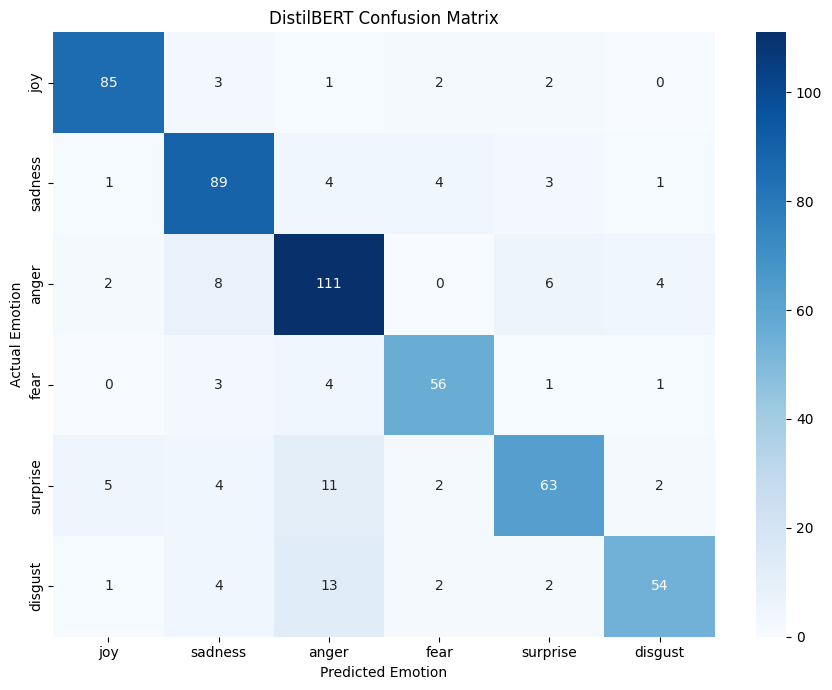

In [69]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.title("DistilBERT Confusion Matrix")

plt.tight_layout()
plt.show()

In [70]:
save_path = "/content/best_distilbert_emotion"

trainer.save_model(save_path)
tokenizer.save_pretrained(save_path)

print("DistilBERT model and tokenizer saved!")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

DistilBERT model and tokenizer saved!


In [71]:
!pip install -q gradio

In [72]:
import torch
import torch.nn.functional as F
import gradio as gr
import numpy as np

emotion_model = trainer.model
emotion_model.to(device)
emotion_model.eval()

class_names = [
    "joy",
    "sadness",
    "anger",
    "fear",
    "surprise",
    "disgust"
]

print("Emotion model is ready!")

Emotion model is ready!


In [73]:
def predict_emotion(text):

    if not text or not text.strip():
        return {}

    # Tokenize input
    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=64
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    emotion_model.eval()

    with torch.no_grad():

        outputs = emotion_model(**inputs)

        probabilities = F.softmax(
            outputs.logits,
            dim=1
        )[0]


    results = {
        class_names[i]: float(probabilities[i].item())
        for i in range(len(class_names))
    }

    return results

In [74]:
demo = gr.Interface(

    fn=predict_emotion,

    inputs=gr.Textbox(
        lines=4,
        placeholder="Write something to detect its emotion...",
        label="Enter Your Text"
    ),

    outputs=gr.Label(
        num_top_classes=6,
        label="Emotion Prediction"
    ),

    title="Emotion Classification with Deep Learning",

    description="""
    An AI-powered emotion classification system using fine-tuned DistilBERT.

    The model detects six emotions:
    Joy, Sadness, Anger, Fear, Surprise, and Disgust.
    """,

    examples=[
        ["I am so happy today! Everything is going perfectly."],
        ["I feel lonely and disappointed with everything."],
        ["I am extremely angry about what happened."],
        ["I am scared about what might happen tomorrow."],
        ["Wow! I never expected this amazing surprise!"],
        ["I am disgusted by this terrible behavior."]
    ],

    theme=gr.themes.Soft(),

    flagging_mode="never"
)

/usr/local/lib/python3.13/dist-packages/gradio/interface.py:171: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  super().__init__(


In [75]:
demo.launch(
    share=True,
    debug=True
)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://c1ed81e5aa386e3029.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://c1ed81e5aa386e3029.gradio.live


In [76]:
save_path = "/content/best_distilbert_emotion"

trainer.save_model(save_path)
tokenizer.save_pretrained(save_path)

print("Model saved successfully!")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved successfully!


In [77]:
import shutil

shutil.make_archive(
    "/content/best_distilbert_emotion",
    "zip",
    "/content",
    "best_distilbert_emotion"
)

print("ZIP file created!")

ZIP file created!


In [78]:
from google.colab import files

files.download("/content/best_distilbert_emotion.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>